# Capítulo 3 · Actividad: ¿qué hago con esta columna?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/04_actividad_decisiones_preprocesamiento.ipynb)

En las actividades anteriores te decíamos qué técnica aplicar. En la vida real nadie te lo dice: **tú decides**. En esta actividad vas a ver columnas de datasets que ya conoces y, para cada una, decidir qué es lo mejor: ¿one-hot u ordinal?, ¿logaritmo o no?, ¿estandarizar, min-max o nada?

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- En cada caso, **ejecuta la celda** que muestra los datos y **míralos con atención** antes de decidir.
- En las celdas ✍️ escribe **qué harías y por qué**. Una decisión sin justificación no vale.
- Algunos casos tienen una celda 🔍 **Comprueba** para verificar tu decisión con un par de líneas de código.
- Muchas veces no hay una única respuesta correcta, pero sí respuestas **mejor o peor justificadas**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

# Datasets que ya conoces
propinas = pd.read_csv(DATA_DIR / "tips.csv")
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv").dropna()
california = pd.read_csv(DATA_DIR / "california_housing.csv")

# Viviendas, con la limpieza de las clases anteriores
viviendas = pd.read_csv(DATA_DIR / "viviendas_sucio.csv").drop_duplicates().dropna()
viviendas["barrio"] = viviendas["barrio"].str.strip().str.capitalize()

---
## Parte 1 · ¿Cómo convierto esta columna en números?

### Caso 1 · La isla de los pingüinos

In [2]:
pinguinos["island"].value_counts()

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

🤔 **Decide:** ¿cómo codificarías `island`: one-hot, ordinal o como binaria? ¿Por qué?

✍️ **Tu decisión:**

one-hot porque no necesita un orden y hay mas de dos opciones

### Caso 2 · El estado de las viviendas

In [3]:
viviendas["estado"].value_counts()

estado
buen estado    220
a reformar     172
como nuevo     138
Name: count, dtype: int64

🤔 **Decide:** ¿cómo codificarías `estado`? Si eliges ordinal, indica qué número le darías a cada valor.

✍️ **Tu decisión:** 

Ordinal, 
a reformar: 0
buen estado: 1
como nuevo: 2

🔍 **Comprueba:** codifica `estado` como decidiste y muestra cuántas viviendas hay de cada valor codificado.

In [4]:
# Tu código aquí

### Caso 3 · ¿Fumadores en la mesa?

In [5]:
propinas["smoker"].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

🤔 **Decide:** ¿cuántas columnas necesitas para representar `smoker`? ¿Cómo la codificarías?

✍️ **Tu decisión:** 
Dos: si y no

### Caso 4 · Personas en la mesa

In [6]:
propinas["size"].value_counts().sort_index()

size
1      4
2    156
3     38
4     37
5      5
6      4
Name: count, dtype: int64

🤔 **Decide:** `size` solo tiene 6 valores distintos. Un compañero propone tratarla como categórica y aplicarle one-hot. ¿Estás de acuerdo?

✍️ **Tu decisión:** 
Si estoy de acuerdo, ya que solo existen 6 valores y se pueden categorizar 

### Caso 5 · El identificador

In [7]:
print("Filas:", len(viviendas), "| Valores distintos de id:", viviendas["id"].nunique())
viviendas[["id", "barrio", "precio"]].head()

Filas: 530 | Valores distintos de id: 530


,id,barrio,precio
0,404,Centro,372000.0
1,458,Sur,128400.0
2,501,Este,438200.0
3,85,Centro,309700.0
4,110,Oeste,306000.0


🤔 **Decide:** queremos predecir el precio. ¿Qué harías con la columna `id`?

✍️ **Tu decisión:** 

El id es independiente al precio o al barrio por lo que no hariamos nada con id

### Caso 6 · La fecha de venta

In [8]:
print("Filas:", len(viviendas), "| Fechas distintas:", viviendas["fecha_venta"].nunique())
viviendas["fecha_venta"].head()

Filas: 530 | Fechas distintas: 427


0    2022-10-24
1    2024-04-12
2    2023-09-12
3    2024-11-02
4    2023-10-12
Name: fecha_venta, dtype: str

🤔 **Decide:** un compañero propone aplicar one-hot a `fecha_venta`. ¿Qué pasaría? ¿Qué harías tú con esta columna?

✍️ **Tu decisión:** 

Deberiamos pasarlo a datetime y extraer las caracteristicas por separado (dia, anio, mes) y despues aplicar one-hot

🔍 **Comprueba:** crea a partir de `fecha_venta` las variables que propusiste.

In [9]:
# Tu código aquí

### Caso 7 · El barrio y el modelo

In [10]:
viviendas["barrio"].value_counts()

barrio
Norte     120
Centro    114
Sur       112
Oeste     103
Este       81
Name: count, dtype: int64

🤔 **Decide:** vas a codificar `barrio` con one-hot.

a) Si el modelo es una **regresión lineal**, ¿usarías `drop_first=True`? ¿Y si es un **árbol de decisión**?

b) El modelo se usará después en una web donde se publicarán viviendas **de barrios nuevos** que no están en estos datos. ¿Usarías `pd.get_dummies` o `OneHotEncoder`? ¿Con qué parámetro?

✍️ **Tu decisión:** 

---
## Parte 2 · ¿La transformo?

### Caso 8 · Ingresos de los distritos de California

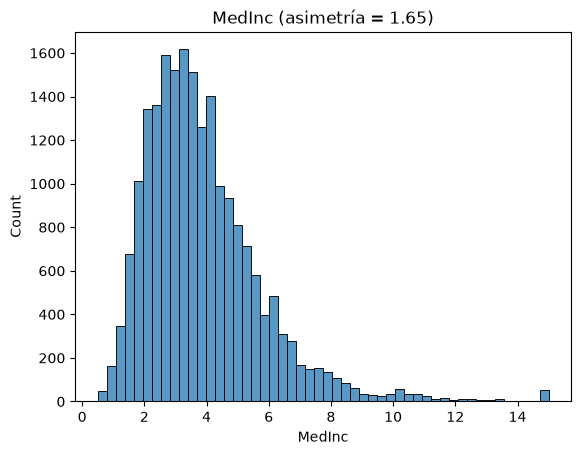

In [11]:
fig, ax = plt.subplots()
sns.histplot(california["MedInc"], bins=50, ax=ax)
ax.set_title(f"MedInc (asimetría = {california['MedInc'].skew():.2f})")
plt.show()

🤔 **Decide:** ¿le aplicarías un logaritmo a `MedInc`? ¿Por qué?

✍️ **Tu decisión:** 

🔍 **Comprueba:** calcula la asimetría de `MedInc` después de aplicarle `np.log1p`.

In [12]:
# Tu código aquí

### Caso 9 · La aleta de los pingüinos

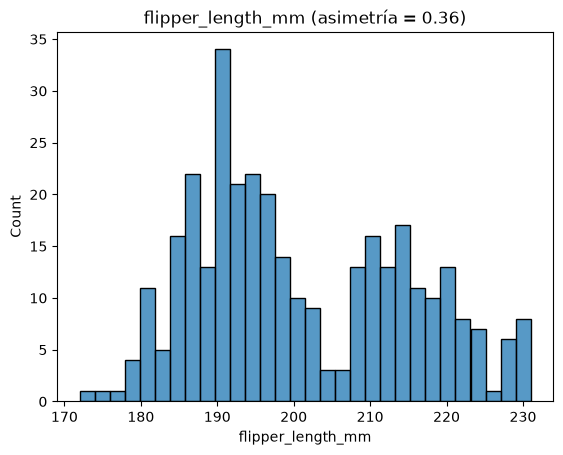

In [13]:
fig, ax = plt.subplots()
sns.histplot(pinguinos["flipper_length_mm"], bins=30, ax=ax)
ax.set_title(f"flipper_length_mm (asimetría = {pinguinos['flipper_length_mm'].skew():.2f})")
plt.show()

🤔 **Decide:** el histograma no parece una campana: tiene dos "montañas". ¿Le aplicarías un logaritmo? ¿Por qué crees que tiene esa forma?

✍️ **Tu decisión:** 

### Caso 10 · Variables nuevas para California

Queremos predecir `MedHouseVal` (el valor de las viviendas). Un compañero propone crear estas tres variables:

| Variable | Fórmula |
|---|---|
| `habitaciones_por_persona` | `AveRooms / AveOccup` |
| `valor_por_habitacion` | `MedHouseVal / AveRooms` |
| `proporcion_dormitorios` | `AveBedrms / AveRooms` |

🤔 **Decide:** ¿cuáles de las tres se pueden usar en el modelo? ¿Por qué?

✍️ **Tu decisión:** 

### Caso 11 · La antigüedad de las viviendas

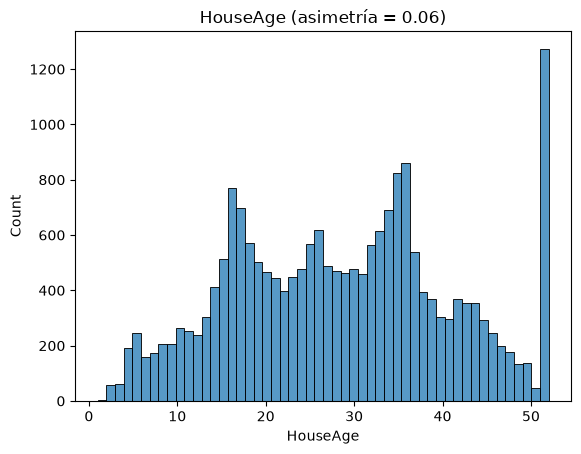

In [14]:
fig, ax = plt.subplots()
sns.histplot(california["HouseAge"], bins=52, ax=ax)
ax.set_title(f"HouseAge (asimetría = {california['HouseAge'].skew():.2f})")
plt.show()

🤔 **Decide:** ¿agruparías `HouseAge` en tramos ("nueva", "media", "antigua") o la dejarías numérica? ¿Le aplicarías un logaritmo?

✍️ **Tu decisión:** 

---
## Parte 3 · ¿Escalo? ¿Cómo?

### Caso 12 · Clasificar pingüinos con KNN

Queremos predecir la especie con **KNN**, un modelo que clasifica cada pingüino según los pingüinos **más cercanos** (calcula distancias entre sus medidas).

In [15]:
pinguinos[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].describe().loc[["mean", "std", "min", "max"]].round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
mean,44.0,17.2,201.0,4207.1
std,5.5,2.0,14.0,805.2
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0


🤔 **Decide:** ¿escalarías estas medidas? Si sí, ¿con qué método? ¿Qué pasaría si no las escalas?

✍️ **Tu decisión:** 

### Caso 13 · Los mismos pingüinos con un árbol de decisión

Ahora usamos un **árbol de decisión**, que clasifica haciendo preguntas del tipo *"¿la aleta mide más de 206 mm?"*.

🤔 **Decide:** ¿hace falta escalar las medidas? ¿Por qué?

✍️ **Tu decisión:** 

### Caso 14 · Imágenes para una red neuronal

Una red neuronal recibe imágenes en escala de grises. Cada píxel es un número de **0 (negro) a 255 (blanco)**:

In [16]:
pixeles = np.random.default_rng(42).integers(0, 256, size=(4, 6))
pixeles

array([[ 22, 198, 167, 112, 110, 219],
       [ 22, 178,  51,  24, 134, 249],
       [188, 194, 183, 201, 131,  32],
       [214, 115, 128,  94,  46, 237]])

🤔 **Decide:** ¿qué escalado usarías: estandarización o min-max? ¿Por qué?

✍️ **Tu decisión:** 

### Caso 15 · ¿Escalo también las categóricas?

Tras codificar las viviendas, tienes columnas de este tipo:

In [17]:
pd.concat([
    viviendas[["metros", "distancia_metro_m"]],
    pd.get_dummies(viviendas["barrio"], prefix="barrio", dtype=int),
    viviendas["garaje"].map({"no": 0, "sí": 1}).rename("garaje"),
], axis=1).head()

,metros,distancia_metro_m,barrio_Centro,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur,garaje
0,104.0,254.0,1,0,0,0,0,1
1,74.0,2369.0,0,0,0,0,1,0
2,174.0,1336.0,0,1,0,0,0,1
3,89.0,850.0,1,0,0,0,0,1
4,114.0,379.0,0,0,0,1,0,0


🤔 **Decide:** vas a estandarizar. ¿Lo aplicarías a **todas** las columnas, también a las de one-hot y a `garaje`? ¿Por qué?

✍️ **Tu decisión:** 

### Caso 16 · ¿En qué orden?

Dos compañeros escriben este código para preparar los datos:

**Compañero A:**
```python
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_escalado, y, test_size=0.2, random_state=42)
```

**Compañero B:**
```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.fit_transform(X_test)
```

🤔 **Decide:** ¿alguno lo hace bien? Explica qué falla en cada uno y escribe (en palabras o en código) el orden correcto.

✍️ **Tu decisión:** 

---
## Parte 4 · Diseña el preprocesamiento completo

Queremos predecir la **propina** (`tip`) con una **regresión lineal**, a partir del resto de columnas de `propinas`.

In [18]:
print(propinas.drop(columns=["tip"]).skew(numeric_only=True).round(2))
propinas.head()

total_bill    1.13
size          1.45
dtype: float64


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


🤔 **Decide:** completa la tabla con el tratamiento de cada columna y añade, si quieres, alguna variable nueva. Justifica las decisiones que no sean obvias.

| Columna | Tipo | Transformación | Codificación | Escalado |
|---|---|---|---|---|
| `total_bill` | | | | |
| `sex` | | | | |
| `smoker` | | | | |
| `day` | | | | |
| `time` | | | | |
| `size` | | | | |
| *(variable nueva)* | | | | |

✍️ **Tu decisión:** 